# 📈 11-02 · 指数平滑：轻量递推预测

> 目标：把「轻模型」用到能打。学完本篇你能——
> ① 手写 **SES / Holt（趋势）/ Holt-Winters（加法+乘法季节）/ 阻尼趋势** 全套递推，并说清每个平滑参数控制什么；
> ② 从 SES 递归式推出加权和 $\alpha(1-\alpha)^k$，并证明 **SES ≡ ARIMA(0,1,1)**（θ=α−1，含参数化差异）；
> ③ 用网格与 `scipy.optimize.minimize` 两种方式自动选参，并与 `statsmodels` 的 ExponentialSmoothing 对照（残差 SSE 同数量级）；
> ④ 用近似公式与蒙特卡洛两种方法给出预测区间，并做 100 次重复覆盖率检验（>0.85）。

> 📍 **主线位置**：前一篇《01 ARMA 与 ARIMA》（回归/频率域视角的模型族）→ 本篇《指数平滑》（**状态递推**视角，轻量、可解释、工业落地多）→ 后一篇《03 时间序列分解》（把信号拆回趋势/季节/残差）。
> 两条大路在本篇第一次汇合：**ARIMA(0,1,1) 与 SES 是同一个模型的两副面孔**。

> 🧩 **生活化类比**：指数平滑 = **带记忆的加权平均**——最近的数据权重最大，老数据指数级衰减（SES 管"水平"）；Holt 加"惯性"（趋势）；Holt-Winters 再加"日历"（季节）；阻尼趋势加"刹车"（趋势会放缓）。就像开车：主要参考最近几秒的路况决定方向盘，而不会把十年前的路况和今天同等当真。

## 核心概念

### (a) 🗂️ 一张图看懂指数平滑家族

```mermaid
flowchart TB
    Node1["🧠 指数平滑：带记忆的加权平均"]
    Node2["📈 SES：ŷ = αy + (1-α)ŷ"]
    Node3["🚀 Holt：+ 趋势 b_t"]
    Node4["🧭 阻尼趋势：+ 刹车 φ"]
    Node5["🌦️ Holt-Winters：+ 季节 s_t"]
    Node6["🎛️ 网格 / scipy 选参"]
    Node7["📏 预测区间 + 覆盖率检验"]
    Node8["🔁 statsmodels 对照"]
    Node1 --> Node2
    Node2 --> Node3
    Node3 --> Node4
    Node4 --> Node5
    Node5 --> Node6
    Node6 --> Node7
    Node7 --> Node8
```

- **指数平滑思想**：带记忆的加权平均——最近的数据权重最大、老数据按指数衰减。展开看就是 $\hat y_{t+1} = \alpha y_t + \alpha(1-\alpha)y_{t-1} + \alpha(1-\alpha)^2 y_{t-2} + \cdots$，权重越老越小但**永不归零**（无限记忆）。
- **SES 简单指数平滑**：$\hat y_{t+1} = \alpha y_t + (1-\alpha)\hat y_t$，一个参数 α 管「水平」。α 大跟手（反应快但抖）、α 小平滑（稳但迟钝）；SES **等价于 ARIMA(0,1,1)**（θ=α−1）。
- **SES 展开与半衰期**：权重 $\alpha(1-\alpha)^k$ 和为 1；权重降到一半需要 $k=\ln 0.5/\ln(1-\alpha)$ 期——α=0.3 只需约 1.9 期，α=0.1 要约 6.6 期。
- **Holt：加趋势**：在 SES 上多一条趋势项 $b_t$，水平 $\ell_t$ 与趋势 $b_t$ 各带平滑参数 α、β，预测 $\hat y_{t+h}=\ell_t+h\,b_t$。
- **阻尼趋势（damped trend）**：给趋势加「刹车系数」φ，预测 $\ell_t+(\varphi+\varphi^2+\cdots+\varphi^h)b_t$，远端趋势被压住——趋势不可持续时比 Holt 更稳。
- **Holt-Winters：加季节**：再加季节项 $s_t$ 与参数 γ。季节可以是**加法**（幅度固定）也可以是**乘法**（幅度随水平缩放），乘法要求 $y_t>0$。
- **参数优化**：α/β/γ/φ 不靠拍脑袋——手写网格扫描 + `scipy.optimize.minimize`（同一目标：一步预测 SSE），并讨论初始化方法（首值/前 m 均值/回归估计）。
- **预测区间**：SES 近似 $\sigma\sqrt{1+\alpha^2(h-1)}$，Holt/HW 用经验式 $\hat y \pm 1.96\sigma\sqrt h$，另用 100 次蒙特卡洛重复做覆盖率检验（>0.85），并与 statsmodels 的输出对照。

## 0. 主线地图

```
数据 → ①SES(水平) → ②Holt(水平+趋势) → ③阻尼(趋势+刹车) → ④HW(水平+趋势+季节)
     → ⑤参数优化(网格/scipy) → ⑥预测区间(公式/MC) → ⑦statsmodels 对照 → ⑧下一篇:分解
```

| 阶段 | 状态变量 | 平滑参数 | 预测式（h 步） | 对应 ETS |
|------|----------|----------|----------------|----------|
| ① SES | $\ell_t$ | α | $\ell_t$（常数） | ETS(A,N,N) |
| ② Holt | $\ell_t, b_t$ | α, β | $\ell_t + h b_t$ | ETS(A,A,N) |
| ③ 阻尼趋势 | $\ell_t, b_t$ + φ | α, β, φ | $\ell_t + (\varphi+\cdots+\varphi^h)b_t$ | ETS(A,Ad,N) |
| ④ HW 加法 | $\ell_t, b_t, s_t$ | α, β, γ | $\ell_t + h b_t + s_{\text{phase}}$ | ETS(A,A,A) |
| ④' HW 乘法 | 同上（比例季节） | α, β, γ | $(\ell_t+h b_t)\times s_{\text{phase}}$ | ETS(A,A,M) |

本篇路线：**先造出"水平"（SES）→ 加"趋势"（Holt）→ 加"刹车"（阻尼）→ 加"季节"（HW）→ 自动选参 → 给区间 → 与库对照 → 反思（不足与演进）**。
每一步都在上一步的状态空间里**多塞一个成分**，这是理解指数平滑家族的最佳心智模型。

### 0.1 历史背景：从"库存预测"长出来的轻模型

指数平滑是**工业界最老也最耐用的预测方法之一**，它的诞生与"二战后的库存管理"直接相关：

- **1956–1959，Brown（罗伯特·布朗，R.G. Brown）**：在美国海军与兰德公司做库存/需求预测时提出**简单指数平滑（SES）**。动机非常工程化：移动平均需要保存 n 个历史值、对最新点等权重，太笨重；SES 只需存**一个数**（当前水平），每来一个新观测只做一次加权更新——"轻、快、可增量计算"。
- **1957，Holt（查尔斯·霍尔特）**：在给五角大楼做的报告中提出**双参数线性趋势法（Holt's method）**，把"水平"与"斜率"分开平滑，解决了 SES 在趋势序列上系统性滞后的问题。
- **1960，Winters（彼得·温特斯）**：把 Holt 推广到带季节性的数据，提出**Holt-Winters**（加法/乘法季节两个版本）。
- **1985，Gardner & McKenzie**：系统研究**阻尼趋势**（damped trend），发现"趋势+阻尼"在真实商业数据上往往比"纯线性趋势"更稳——因为现实里的趋势（销量、需求）几乎不会无限线性外推。
- **2008，Hyndman 等**：把整个家族统一进 **ETS 状态空间框架**（Error/Trend/Seasonal 三选一），给出概率解释与似然估计，让指数平滑从"启发式"升级为"可检验的统计模型"。

**一句话记忆**：Brown 发明"水平"，Holt 加"趋势"，Winters 加"季节"，Gardner 加"刹车"，Hyndman 统一成"ETS"——五个人名就是指数平滑的全部演化史。

### 0.2 ETS 框架：误差 × 趋势 × 季节 三选一

ETS 用三个字母描述一个模型：**E**rror（误差：A 加法 / M 乘法）、**T**rend（趋势：N 无 / A 加法 / Ad 阻尼加法）、**S**eason（季节：N 无 / A 加法 / M 乘法）。

| 模型 | 误差 E | 趋势 T | 季节 S | 状态个数 | 典型场景 |
|------|--------|--------|--------|----------|----------|
| SES | A | N | N | 1（ℓ） | 平稳、无趋势无季节 |
| Holt | A | A | N | 2（ℓ,b） | 有线性趋势 |
| 阻尼趋势 | A | Ad | N | 2（ℓ,b）+φ | 趋势会放缓 |
| HW 加法 | A | A | A | 3（ℓ,b,s） | 趋势+固定振幅季节 |
| HW 乘法 | A | A | M | 3（ℓ,b,s） | 趋势+振幅随水平增长 |

本篇手写的正是这张表里最常见的四种：**SES = ETS(A,N,N)、Holt = ETS(A,A,N)、阻尼 = ETS(A,Ad,N)、HW = ETS(A,A,A) 与 ETS(A,A,M)**。
ETS 的价值在于：它给"递推公式"配上了**似然与预测分布**（区间），并解释了为什么"一步预测 SSE"是合理的拟合目标（高斯加法误差下的极大似然等价于最小化一步 SSE）。

### 0.3 记号与"一步预测"约定（先对齐再学公式）

全篇统一记号：$\ell_t$=水平，$b_t$=趋势（斜率），$s_t$=季节项，$m$=季节周期，$h$=预测步长，$e_t = y_t - \hat y_t$=一步预测误差。

**代码里的一步预测对齐**：我们手写的 `ses()`/`holt()`/`hw_add()` 约定 $f[t]$ 存的是 **$\hat y_t$——用 $t-1$ 时刻及之前的数据对 $y_t$ 做的一步预测**，因此：
- $f[0]=y[0]$ 作为初始化（等价于 $\hat y_1 = y_0$）；
- 残差直接是 `e = y - f`（**逐位对齐**，不需要移位）；
- 多步预测 `fc[k]` 才是 $h=k+1$ 步外推。

> 💡 很多教程里 $f[t]$ 存的是 $\hat y_{t+1}$，两种约定只差一个下标。本篇统一用"对齐 y_t 的一步预测"，这样推导 SES≡ARIMA 的恒等式时不会因为下标错位而出错（这是最容易翻车的手写细节）。

## 1. SES：简单指数平滑

$$\hat y_{t+1} = \alpha y_t + (1-\alpha)\hat y_t,\qquad \alpha\in(0,1)$$

**直觉**：新预测 = α ×（最新观测）+ (1−α) ×（旧预测）。α 越大越"相信最新数据"，α 越小越"相信历史平滑值"。它只有**一个状态**（当前水平），每次更新 O(1)，存一个数即可——这就是 Brown 当年做库存预测要的"轻"。

把递归式展开（见 1.1）会看到它等价于对历史数据做**几何衰减加权平均**：

$$\hat y_{t+1} = \alpha y_t + \alpha(1{-}\alpha)y_{t-1} + \alpha(1{-}\alpha)^2 y_{t-2} + \cdots$$

对比滑动平均（MA）：MA 对窗口内等权重、窗口外权重为 0；SES 权重**处处非零但指数衰减**——老数据不会突然"被遗忘"，只会越来越不重要。

### 1.1 SES 展开推导：α(1-α)^k 加权和从哪来

**第 1 步：递归一次**。$\hat y_t = \alpha y_{t-1} + (1-\alpha)\hat y_{t-1}$，代入 $\hat y_{t+1}$：

$$\hat y_{t+1} = \alpha y_t + (1-\alpha)\big[\alpha y_{t-1} + (1-\alpha)\hat y_{t-1}\big] = \alpha y_t + \alpha(1-\alpha)y_{t-1} + (1-\alpha)^2 \hat y_{t-1}$$

**第 2 步：递归 k 次**，直到 $\hat y_1 = y_0$（初始化）：

$$\hat y_{t+1} = \underbrace{\alpha y_t + \alpha(1{-}\alpha)y_{t-1} + \cdots + \alpha(1{-}\alpha)^{t-1} y_1}_{\text{共 }t\text{ 项，权重 }\alpha(1-\alpha)^k} \;+\; (1-\alpha)^{t}\,\hat y_1$$

**第 3 步：验证权重和为 1**（等比级数）：

$$\sum_{k=0}^{t-1}\alpha(1-\alpha)^k + (1-\alpha)^t = \alpha\cdot\frac{1-(1-\alpha)^t}{1-(1-\alpha)} + (1-\alpha)^t = 1-(1-\alpha)^t + (1-\alpha)^t = 1$$

**第 4 步：半衰期（记忆长度）**。权重降到一半需要 $\;(1-\alpha)^k = 0.5 \Rightarrow k = \dfrac{\ln 0.5}{\ln(1-\alpha)}$：

| α | 权重序列 α(1-α)^k（k=0,1,2,…） | 半衰期 k |
|---|--------------------------------|----------|
| 0.1 | 0.100, 0.090, 0.081, 0.073, 0.066, … | ≈ 6.6 期 |
| 0.3 | 0.300, 0.210, 0.147, 0.103, 0.072, … | ≈ 1.9 期 |
| 0.8 | 0.800, 0.160, 0.032, 0.006, … | ≈ 0.3 期（几乎只信最近 1-2 期） |

> 口算手算题（面试高频）：α=0.3，最近 3 个观测的权重 = 0.3 + 0.21 + 0.147 = **0.657**，即一半以上的预测权重落在最近 3 期；α=0.1 时同样 3 期只占 0.271。**α 就是"记忆开关"**。

### 1.2 SES ≡ ARIMA(0,1,1)：同一个模型的两副面孔（重点推导）

令 $e_t = y_t - \hat y_t$ 为 SES 的一步预测误差。

**第 1 步：把递归式改写成"误差修正"形式**。

$$\hat y_{t+1} = \alpha y_t + (1-\alpha)\hat y_t = \hat y_t + \alpha(y_t - \hat y_t) = \hat y_t + \alpha e_t$$

即**新预测 = 旧预测 + α × 上一步的预测误差**——这正是"误差修正"（error correction）直觉：预测错了多少，就用它的 α 倍去修正下一次预测。

**第 2 步：对差分序列展开**。$y_t = \hat y_t + e_t$，代入：

$$\nabla y_t = y_t - y_{t-1} = (\hat y_t + e_t) - (\hat y_{t-1} + e_{t-1}) = (\hat y_t - \hat y_{t-1}) + e_t - e_{t-1} = \alpha e_{t-1} + e_t - e_{t-1}$$

$$\boxed{\;\nabla y_t = e_t + (\alpha-1)\,e_{t-1}\;}$$

**第 3 步：读出 ARIMA(0,1,1)**。上式就是

$$\nabla y_t = \varepsilon_t + \theta\,\varepsilon_{t-1},\qquad \theta = \alpha - 1$$

其中 $\varepsilon_t\equiv e_t$。这就是 **ARIMA(0,1,1)**（一阶差分 + 一个 MA 项），MA 系数 **θ = α−1 ∈ (−1, 0)**（因为 α∈(0,1)）。

**第 4 步：说清参数化差异（面试追问点）**。
- statsmodels 的写法 $\nabla y_t = \varepsilon_t + \theta\varepsilon_{t-1}$，拟合参数就是 θ=α−1（**负数**）；
- 有些教材写 $\nabla y_t = \varepsilon_t - \theta'\varepsilon_{t-1}$，则 θ′=1−α（**正数**）；
- 两种写法差一个负号，**背公式前先确认库的约定**；
- 另一个坑：MA(1) 的高斯似然对 θ 与 1/θ **对称**（两个根同似然），无约束优化可能收敛到不可逆根（|θ|>1）。所以实验 2 用 `SARIMAX(enforce_invertibility=True)` 而不是裸 `ARIMA`——这是真实的工程坑。

### 1.3 SES 小结与不足

**优点**：只存一个数、O(1) 更新、可解释（α=记忆）、是 ETS(A,N,N)。适合**平稳无趋势**的监控/库存基线。

**不足（三个字：跟不上）**：
1. **有趋势时系统性滞后**——平滑值永远落后于上升/下降的真实水平（实验 1 可见 α 越大滞后越小但抖得越厉害）；
2. **预测是常数**——$\hat y_{t+h}=\ell_t$ 对所有 h 相同，无法外推趋势；
3. **没有季节概念**——周期数据会被当成噪声。

解决：加趋势 → Holt（第 2 节）；趋势不可持续 → 阻尼（2.3）；再加季节 → Holt-Winters（第 3 节）。

## 2. Holt：加趋势

$$\ell_t = \alpha y_t + (1-\alpha)(\ell_{t-1} + b_{t-1})$$
$$b_t = \beta\,(\ell_t - \ell_{t-1}) + (1-\beta)\,b_{t-1}$$
$$\hat y_{t+h} = \ell_t + h \cdot b_t$$

**直觉**：两个状态、两个参数，分工明确——
- $\ell_t$：**水平**（去趋势后的"现在值"），由 α 平滑；
- $b_t$：**趋势/斜率**，由 β 平滑（"相邻水平差" $\ell_t-\ell_{t-1}$ 是趋势的现测值，β 决定多信它）；
- 预测 = 当前水平 + 趋势 × 步数：**线性外推**。

水平更新里用的是 $\ell_{t-1}+b_{t-1}$（**带趋势外推的水平**）而非裸 $\ell_{t-1}$——这是 Holt 与 SES 的本质区别：SES 认为"下一时刻还是 ℓ"，Holt 认为"下一时刻是 ℓ 再加一个 b"。

> 面试一句话：Holt = 两个 SES 叠起来——一个平滑水平、一个平滑斜率；斜率 = 水平的一阶差分。

### 2.1 手算 Holt 两步（α=0.3，β=0.2）

数据 $y=[10,\ 12,\ 11.5,\ \cdots]$，初始化 $\ell_0=10,\ b_0=y_1-y_0=2$。

**t=1（用 y₁=12）**：
$$\ell_1 = 0.3\times 12 + 0.7\times(10+2) = 3.6 + 8.4 = 12.0$$
$$b_1 = 0.2\times(12.0-10) + 0.8\times 2 = 0.4 + 1.6 = 2.0$$
$$\hat y_3 = \ell_1 + b_1 = 14.0$$

**t=2（用 y₂=11.5）**：
$$\ell_2 = 0.3\times 11.5 + 0.7\times(12.0+2.0) = 3.45 + 9.8 = 13.25$$
$$b_2 = 0.2\times(13.25-12.0) + 0.8\times 2.0 = 0.25 + 1.6 = 1.85$$
$$\hat y_4 = \ell_2 + b_2 = 15.10$$

观察：y₂ 从 12 掉到 11.5，但 $\ell_2=13.25$ 仍在上升——**水平没有完全跟着观测走，趋势还在延续**，这正是 Holt 比 SES 强的地方：它分开平滑"现在值"和"走向"。

### 2.2 网格选参思路（不靠拍脑袋）

α、β ∈ (0,1) 需要定。标准做法：**留出集（hold-out）网格搜索**——
1. 把数据切成 训练段 / 留出段（例如各 120/24）；
2. 在网格 α,β ∈ {0.05,0.15,…,0.95} 上逐组跑 Holt，用训练段拟合、预测留出段；
3. 选**留出 MAE（或一步 SSE）最小**的一组参数。

两个注意点：
- **留出误差含噪声累积**（多步预测误差随 √h 增长），阈值要放宽；
- 网格越密越接近全局最优，但代价是组合爆炸（2 维还好，3-4 维建议换优化器，见第 4 节）。

实验 3 会跑这个流程；实验 7 再用 `scipy.optimize.minimize` 对"一步 SSE"直接优化，两者结果应高度一致。

### 2.3 阻尼趋势（damped trend）：给趋势装刹车

Holt 的线性外推 $\ell_t+h\,b_t$ 在 h 大时会无限涨——现实中的趋势（销量、活跃用户、库存）**几乎不可能永远线性**。Gardner-McKenzie（1985）加一个"刹车系数" φ∈(0,1]：

$$\ell_t = \alpha y_t + (1-\alpha)(\ell_{t-1} + \varphi\, b_{t-1})$$
$$b_t = \beta(\ell_t - \ell_{t-1}) + (1-\beta)\,\varphi\, b_{t-1}$$
$$\hat y_{t+h} = \ell_t + (\varphi + \varphi^2 + \cdots + \varphi^h)\, b_t$$

**直觉**：趋势每外推一步都被乘一次 φ，越远越被压扁。h 步累积系数是等比级数：
- φ=1：退化为普通 Holt（$1+1+\cdots+1=h$）；
- φ<1：$\varphi+\cdots+\varphi^h = \varphi\dfrac{1-\varphi^h}{1-\varphi}$，且 $h\to\infty$ 时有**上界** $\dfrac{\varphi}{1-\varphi}\,b_t$——远端预测被"焊死"在水平线附近。

**手算**：b=1.0、h=3、φ=0.8：累积 = 0.8+0.64+0.512 = **1.952** < 3（无阻尼）。φ=0.8 时远期上界 = 0.8/0.2 = 4.0 倍 b——比无阻尼的无限外推保守得多。

> 面试一句话：**阻尼趋势 = Holt + 一个"趋势衰减率"φ**；趋势越不可持续，φ 越应远离 1。

### 2.4 阻尼趋势小结：什么时候用

| 场景 | 无阻尼 Holt | 阻尼趋势（φ<1） |
|------|-------------|------------------|
| 趋势真的会持续很久 | 更准 | 系统性欠外推 |
| 趋势只是近期惯性、会放缓 | 远期爆炸式高估 | **更准（留出 MAE 明显更低）** |
| 需要"渐进到平台"的预测 | 不适用 | 天然带平台上限 φ/(1-φ)·b |

实验 4 构造一个**训练段陡趋势、留出段趋势塌掉**的序列：阻尼趋势的留出 MAE 应明显优于无阻尼 Holt。判定标准：**预测越远、业务越不确定，越该开阻尼**。

## 3. Holt-Winters：加季节（加法版）

$$\ell_t = \alpha\,(y_t - s_{t-m}) + (1-\alpha)(\ell_{t-1} + b_{t-1})$$
$$b_t = \beta\,(\ell_t - \ell_{t-1}) + (1-\beta)\,b_{t-1}$$
$$s_t = \gamma\,(y_t - \ell_t) + (1-\gamma)\,s_{t-m}$$
$$\hat y_{t+h} = \ell_t + h\,b_t + s_{t-m+((h-1)\bmod m)+1}$$

**直觉**：三个状态 $\ell_t$（水平）、$b_t$（趋势）、$s_t$（季节），三个参数 α/β/γ，分工与 Holt 相同，只是多了季节项：
- 水平更新先**去季节**：$y_t - s_{t-m}$（用上一周期同相位的季节值）；
- 季节更新存**偏差**：$y_t - \ell_t$（当前观测相对水平的偏离），再用 γ 与上一周期的 $s_{t-m}$ 混合；
- 预测 = 趋势外推 + **对应相位的季节项**（$h$ 步后的相位 = $((h-1)\bmod m)+1$）。

**m = 季节周期**（如 24 表示日度数据按 24 小时、月度数据按 12）；**初始化**：水平=前 m 个均值，趋势=前 m 个一阶差分均值，季节=前 m 个去趋势偏差（见 3.3）。

### 3.1 乘法 Holt-Winters：季节项用"比例"而非"偏差"

当**季节振幅随水平增长**（夏天销量 100、冬天 50；水平涨到 200，冬天就变 100）时，加法"±固定值"会跟不上——这时用乘法版：季节项 $s_t$ 是**比例**（围绕 1 波动），递推里的加减全换成乘除：

$$\ell_t = \alpha\,\dfrac{y_t}{s_{t-m}} + (1-\alpha)(\ell_{t-1}+b_{t-1})$$
$$b_t = \beta\,(\ell_t - \ell_{t-1}) + (1-\beta)\,b_{t-1}$$
$$s_t = \gamma\,\dfrac{y_t}{\ell_t} + (1-\gamma)\,s_{t-m}$$
$$\hat y_{t+h} = (\ell_t + h\,b_t)\times s_{t-m+((h-1)\bmod m)+1}$$

**硬性要求：$y_t>0$ 对所有 t**（除法不能过零/负）。如果数据含 0 或负数：先加常数平移，或取 log 把乘法变加法再跑加法版，或直接换加法版。

**手算乘法版一步**：设 $\ell_{t-1}=9.5, b_{t-1}=0.1, s_{t-m}=0.95, y_t=10, \alpha=0.3, \gamma=0.2$：
- 去季节化水平：$y_t/s_{t-m}=10/0.95\approx 10.526$，$\ell_t = 0.3\times 10.526 + 0.7\times(9.5+0.1)=3.158+6.72=9.878$；
- 季节更新：$y_t/\ell_t=10/9.878\approx 1.012$，$s_t = 0.2\times 1.012 + 0.8\times 0.95 = 0.9625$。

> 对比加法版同一步：$s_t=0.2\times(10-9.878)+0.8\times 0.95=0.7844$——乘法版季节项是**比值**、加法版是**偏差**，数值含义完全不同。

### 3.2 加法 vs 乘法：什么时候乘法更优

| 判据 | 加法（s 是偏差） | 乘法（s 是比例） |
|------|------------------|-------------------|
| 季节振幅 | 固定（±常数） | 随水平缩放（×常数） |
| 数据要求 | 无 | **必须恒正** |
| 水平翻倍时季节项 | 不变（振幅跟不上） | 自动翻倍（振幅跟着走） |
| 适用 | 温度、电费（振幅稳定） | 销量、GMV（振幅随规模涨） |

实验 6 构造**振幅随水平增长**的合成数据（$y_t=(30+0.05t)\times(1+0.3\sin(\cdot))$），在同一网格上分别拟合加法/乘法版并比较留出 MAE——**乘法版应明显胜出**。

> 工程技巧：拿不准时先看"季节幅度是否与水平成正比"：把每周期峰谷差对水平回归，斜率≈0 用加法、明显>0 用乘法。

### 3.3 季节项初始化与周期 m 的坑

**初始化方法（三种常见）**：
1. **首值法**：$\ell_0=y_0$，$b_0=y_1-y_0$——最简单，但前几步状态偏差大；
2. **前 m 均值法**（本篇默认）：$\ell_0=\text{mean}(y_{0:m})$，$b_0=\text{mean}(\text{diff}(y_{0:m}))$，$s_j=y_j-\ell_0$（加法）或 $y_j/\ell_0$（乘法）——用完整个首个周期，季节初值合理；
3. **回归法 / 'estimated'**：对 $t$ 与季节哑变量做线性回归取系数作初值（statsmodels 默认），初值质量最高，配合很小的平滑参数也能拟合得很好（实验 10 会看到这个现象）。

**两个必须记住的坑**：
- **周期 m 定错 = 全错**：m 必须与真实周期一致（24 小时、12 月、7 天）；m 定错，季节项互相打架，预测直接崩；
- **NumPy 负索引陷阱**：手写递推时 $s_{t-m}$ 在 $t<m$ 时下标为负——**NumPy 会把负索引环绕到数组尾部**，取到 0 值甚至越界数据。基础版实现里第一周期其实是"错误的 0 季节值"在参与递推。增强版用**偏移数组**（$s[i]$ 存"时刻 $i-m$"的季节值）彻底规避（实验 5 的代码即如此）。

> 面试追问：为什么 statsmodels 的 ExponentialSmoothing 不传 α/β/γ 也能跑？——因为它有 `initialization_method='estimated'`，把初值也当参数优化了。

## 4. 参数优化：网格 vs scipy.minimize（同一目标 SSE）

**拟合目标**：高斯加法误差下，最大化似然等价于最小化**一步预测 SSE**：

$$\mathrm{SSE}(\alpha,\beta,\dots) = \sum_{t=1}^{n}\big(y_t - \hat y_t\big)^2$$

**方法一：手写网格**。把参数空间离散化扫描（二维 50×50=2500 次 O(n) 递推，秒级完成）：
- 优点：直观、不怕局部极值、可画出损失面；
- 缺点：维度一高组合爆炸（3 维 × 50 每维 = 12.5 万次）。

**方法二：`scipy.optimize.minimize`**。L-BFGS-B 带边界 (0.01, 0.99)，多次随机起点（multi-start）防局部极值：
- 优点：高维高效、精确定到亚网格精度；
- 缺点：可能陷局部极值 → **多起点 + 网格初值**是标准组合。

实验 7 在同一目标 SSE 上跑两种方法，断言参数与 SSE 高度一致（|Δα|<0.05、SSE 相对差 <2%）。

### 4.1 初始化方法讨论（为什么"初值"和"参数"一样重要）

指数平滑的递推是**链式依赖**：初值（$\ell_0,b_0,s_{0:m}$）错了，会顺着整条链污染所有状态，参数优化也会被带偏。初始化方法按质量排序：

1. **首值法**：$\ell_0=y_0,\ b_0=y_1-y_0$，$s_j=0$（或 1）——最省事，前几步偏差最大；
2. **前 m 均值法**：$\ell_0=\mathrm{mean}(y_{0:m})$，$b_0=\mathrm{mean}(\Delta y_{0:m})$，$s_j=y_j-\ell_0$（比例则 $y_j/\ell_0$）——用满第一个周期，本篇默认；
3. **回归法 / 'estimated'**：把 $y_t$ 对 $t$ 与季节哑变量回归，回归系数直接做初值（statsmodels 默认）——初值质量最高，有时**初值足够好到平滑参数接近 0 也能拟合得很好**（实验 10 会看到优化器把 α/β/γ 压到接近 0 的极端现象）。

> 面试表述：**"初值只影响前几步、对长序列影响衰减；但若参数优化与初值一起做（如 statsmodels），初值质量会直接影响收敛与最终 SSE。"**

## 5. 预测区间：SES 的 σ√(1+α²(h-1)) 从哪来

**第 1 步：写出 SES 的 ARIMA 形式**（1.2 节）：$\nabla y_t = \varepsilon_t + \theta\varepsilon_{t-1}$，$\theta=\alpha-1$，Var(ε)=σ²。

**第 2 步：求 h 步预测误差的 ψ-权重**。由 $\nabla = 1-B$，模型可写成 $y_{t+h}-\hat y_{t+h}=\sum_{j=0}^{h-1}\psi_j\,\varepsilon_{t+h-j}$，其中
$$(1-B)^{-1}(1+\theta B) = (1+B+B^2+\cdots)(1+\theta B) = 1 + (1+\theta)B + (1+\theta)B^2+\cdots$$
所以 $\psi_0=1$，$\psi_j = 1+\theta = \alpha$（j≥1）。

**第 3 步：误差方差 = σ² × ψ 权重平方和**：
$$\mathrm{Var}(\hat y_{t+h}-y_{t+h}) = \sigma^2\sum_{j=0}^{h-1}\psi_j^2 = \sigma^2\big[1 + \alpha^2(h-1)\big]$$

**第 4 步：95% 区间**：
$$\hat y_{t+h} \;\pm\; 1.96\,\sigma\sqrt{1+\alpha^2(h-1)}$$

**直觉**：h=1 时区间宽度 σ（只含当前期噪声）；之后**每多一步只多 $\alpha^2\sigma^2$**（因为远期误差只经过 α 的"记忆"传播）。α 越小（越平滑），区间随 h 增长越慢——**平滑模型的区间比裸随机游走（√h）涨得慢**。

> 与裸 ±1.96σ√h 的对比：SES 区间把"记忆系数 α"算进去了；α→1 时 $\sqrt{1+(h-1)}$ 恰退化为 √h（随机游走情形）。实验 8 用 100 次蒙特卡洛重复检验覆盖率。

### 5.1 蒙特卡洛区间与覆盖率检验协议

近似公式依赖于模型假设（高斯误差、模型正确）。**蒙特卡洛（MC）是通用替代**：从拟合残差里抽样（bootstrap）或直接假设 N(0,σ²)，模拟很多条未来路径，取 2.5%/97.5% 分位数做经验区间。

**覆盖率检验协议（本篇采用）**：
1. 固定种子，**重复 100 次**：每次重新生成数据 → 训练段拟合（网格选 α、估 σ）→ 用区间公式包住留出段 h=1..40 的真实值；
2. 统计"真实值落入区间"的比例，**平均覆盖率应 >0.85**（高斯近似下理论值约 0.95；样本小、近似公式偏保守时会略高于或低于 0.95，但应远高于 0.85 红线）；
3. 单次 40 点覆盖率波动很大，**必须重复多次取平均**才稳定——这就是为什么要"100 次重复"。

> 面试表述：**"覆盖率 = 频率学意义上的校准检验：区间宣称 95%，实测落入比例要接近 95%。"**

### 5.2 Holt/HW 的经验式 ±1.96·σ·√h（基础版保留）

对 Holt/HW（状态更多、公式更复杂），教材常用**经验近似**：用拟合残差估 σ，认为 h 步预测误差标准差 ≈ σ√h（不确定性按 √h 累积）：

$$\hat y_{t+h} \pm z\,\sigma\sqrt h,\qquad z=1.96\text{ 对应 95\%}$$

- σ 从拟合残差估计；
- 宽度随 √h 增长：越远越没底；
- 实验 9 保留原基础版做法，并**扩展**：与"固定宽度区间"（±1.96σ）对比，证明 √h 扩张确实提升了覆盖率。

> 对比：SES 的严格式 σ√(1+α²(h-1)) 增长率 < σ√h（α<1）；Holt/HW 的 √h 是"不确定性累积"的通用、偏保守近似。

### 5.3 预测区间对比小结

| 方法 | 公式 | 增长率 | 适用 | 覆盖率 |
|------|------|--------|------|--------|
| SES 近似（严格推导） | $\sigma\sqrt{1+\alpha^2(h-1)}$ | 缓（α<1） | 平稳数据 | ≈95%（实验 8 >0.85 通过） |
| Holt/HW 经验式 | $\pm1.96\sigma\sqrt h$ | √h | 趋势/季节 | 偏保守，实验 9 验证 |
| 蒙特卡洛 | 模拟路径的 2.5%/97.5% 分位 | 自适应 | 任何模型 | 校准最好 |

**工程建议**：报告预测必须带区间；优先用 MC 或库内建区间，手写实验用近似式并做覆盖率检验兜底。

## 6. 与 statsmodels ExponentialSmoothing 对照

手写实现的正确性需要一个"权威裁判"：`statsmodels.tsa.holtwinters.ExponentialSmoothing`。对照策略：

1. **同参数对照**：把手写版用的 (α, β, γ) 原封不动塞给 statsmodels（`optimized=False`），比**一步残差 SSE**——同参数下两边应同数量级（比值 <2），差异只来自初始化；
2. **预测对照**：同参数下 h 步预测逐点比对（最大差 <2，48 步的量级）；
3. **优化对照**：statsmodels `optimized=True`（默认 `initialization_method='estimated'`）优化一步 SSE，其 SSE 应 ≤ 手写网格的结果（网格更粗、优化更细）。

> 注意：statsmodels 默认把**初值也当参数估计**（回归法初始化），所以它的"优化后 SSE"往往比手写网格低——这正是 4.1 节说的"初始化质量影响最终 SSE"的实证。

### 6.1 对照结果解读

实验 10 会看到三类典型现象（在合成数据上稳定复现）：
- **同参数 SSE 比值 ≈ 1.0~1.2**：手写实现与 statsmodels 基本一致，验证递推正确；
- **优化后 SSE 更低**：statsmodels 的 'estimated' 初值 + 连续优化比 0.1 粒度网格更精细；
- **极端参数**：有时优化器把平滑参数压到接近 0——因为回归法初值已经把水平/趋势/季节"预拟合"得很好，平滑参数只需很小——这是初始化方法影响的可视证据，不是 bug。

**结论**：手写版与库版在同一量级，说明递推、初始化、预测逻辑都正确；库版进一步提供似然、AIC/BIC 与原生预测区间，生产环境直接用库即可。

## 7. 数字敏感度与易错点（面试官爱问的坑）

1. **权重和恒为 1、半衰期要会算**：$(1-\alpha)^k=0.5 \Rightarrow k=\ln0.5/\ln(1-\alpha)$；α=0.3 → 约 1.9 期，α=0.1 → 约 6.6 期。α 就是"记忆长度"开关。
2. **θ=α−1 是负数**：SES≡ARIMA(0,1,1) 的 MA 系数 θ=α−1∈(−1,0)；教材若写 $\varepsilon_t-\theta'\varepsilon_{t-1}$，则 θ′=1−α。**先确认库的参数化再背公式**。
3. **MA(1) 似然对称性**：θ 与 1/θ 同似然，裸 `ARIMA` 可能收敛到不可逆根（|θ|>1）；用 `SARIMAX(enforce_invertibility=True)` 才稳妥。
4. **乘法 HW 要求 $y_t>0$**（除法分母不能为 0/负）；数据含 0 或负 → log 化转加法，或加常数平移。
5. **季节周期 m 定错 = 全错**：m 必须与真实周期一致；网格/优化器救不了错误的 m。
6. **NumPy 负索引陷阱**：手写递推 $s_{t-m}$ 在 t<m 时下标为负会**环绕到数组尾部**取错值——用偏移数组（$s[i]$ 存时刻 $i-m$ 的值）。
7. **初始化质量影响优化**：首值法/前 m 均值法/回归法差异明显；statsmodels 默认 'estimated'，有时初值好到平滑参数被优化到接近 0。
8. **覆盖率是频率学校准**：100 次重复平均覆盖率 >0.85 才可信；单次 40 点覆盖率的波动很大，别拿单次结果下结论。

## 8. 面试速答（30 秒背诵版）

- **SES**：$\hat y_{t+1}=\alpha y_t+(1-\alpha)\hat y_t$；等价 ARIMA(0,1,1)，θ=α−1；展开权重 $\alpha(1-\alpha)^k$，和=1。
- **Holt**：加趋势 $b_t$；预测 $\ell_t+h b_t$；参数 α（水平）、β（斜率）。
- **阻尼趋势**：$\ell_t=\alpha y_t+(1-\alpha)(\ell_{t-1}+\varphi b_{t-1})$；预测 $\ell_t+(\varphi+\cdots+\varphi^h)b_t$；φ=1 退化 Holt，远端有上界 φ/(1-φ)·b。
- **Holt-Winters**：加季节 $s_t$（加法=偏差 / 乘法=比例）；乘法要求 $y>0$；振幅随水平增长用乘法。
- **α 的直觉**：越大越跟手、越小越平滑；网格/最小化一步 SSE 自动选。
- **参数优化**：手写网格 vs `scipy.optimize.minimize`（L-BFGS-B + 多起点）同一目标 SSE；初值方法：首值/前 m 均值/回归估计。
- **区间**：SES $\pm1.96\sigma\sqrt{1+\alpha^2(h-1)}$；Holt/HW 经验式 $\pm1.96\sigma\sqrt h$；MC 模拟分位数；覆盖率检验 >0.85。
- **与 statsmodels**：同参数残差 SSE 同数量级（比值 <2）；库默认 'estimated' 初值 + 连续优化更精细。
- **适用**：单变量、低延迟、可解释性要求高的场景（销售/库存/监控基线）；ETS 框架统一了误差×趋势×季节三选一。

**易错点**：季节周期 m 定错 → 全错；乘法季节要求序列恒正；θ=α−1 是负号别记反；初始化方式影响前几步与优化收敛。

## 9. 自测清单

- [ ] 默写 SES/Holt/HW（加法+乘法）/阻尼趋势四套递推公式，说清每个参数控制什么
- [ ] 手推 SES 展开 $\alpha(1-\alpha)^k$ 并验证权重和为 1；口算 α=0.3 的半衰期
- [ ] 手推 SES≡ARIMA(0,1,1)：∇y_t = e_t + (α−1)e_{t-1}，说清 θ=α−1 与 θ=1−α 两种参数化差异
- [ ] 手写 Holt 并网格选 α/β（留出集 MAE）；与 scipy 优化器对照（同一 SSE 目标）
- [ ] 手写阻尼趋势，网格/优化选 φ；构造"趋势塌掉"数据证明阻尼优于无阻尼（留出 MAE）
- [ ] 手写 Holt-Winters 加法季节预测 2 个周期；用偏移数组规避负索引 bug
- [ ] 手写乘法 HW 一步递推（除法季节），说明 y>0 的原因；在振幅增长数据上证明乘法更优
- [ ] 手写 95% 区间：SES 用 σ√(1+α²(h-1))，Holt/HW 用 ±1.96σ√h；做 100 次重复覆盖率检验（>0.85）
- [ ] 用 statsmodels ExponentialSmoothing 对照手写版（同参数 SSE 比值 <2，h 步预测最大差 <2）
- [ ] 说清三种初始化方法（首值/前 m 均值/回归估计）对前几步与优化的影响
- [ ] 说出至少 4 个易错点（m 定错、乘法要求恒正、θ 符号、负索引、覆盖率的频率学含义）

> 💡 下一篇 `03-时间序列分解` 从"预测"回到"拆解"：趋势/季节/残差各归其位，并解释本篇"为什么要 m 个季节值、为什么要去季节"。

## 10. 延伸阅读与知识图谱

**知识图谱（相关概念串联）**：

```
移动平均(等权,忘得快) ──► 指数平滑(几何衰减,永远记得) ──► ETS 状态空间(Hyndman 2008)
      │                        │
      │                        ├─► SES ──► ARIMA(0,1,1)（θ=α−1）
      │                        ├─► Holt ──► 阻尼趋势(Gardner 1985, φ)
      │                        └─► Holt-Winters(加法/乘法, m 周期)
      └─► Box-Jenkins(01篇) ──► SARIMA（季节差分）──► 与 HW 都是"季节建模"的两条路线
```

**延伸阅读建议**：
- Holt (1957) 与 Winters (1960) 原始报告（可读综述：Hyndman 等《Forecasting with Exponential Smoothing》2008）；
- Brown (1959)《Statistical Forecasting for Inventory Control》——SES 的出处（库存场景）；
- Gardner & McKenzie (1985) 阻尼趋势的实证研究；
- 教材《Forecasting: Principles and Practice》第 7-8 章（ETS 框架与预测区间）——免费在线；
- statsmodels `ExponentialSmoothing` 文档：`initialization_method`、`optimized`、`use_boxcox` 参数含义。

**面试进阶三问**：
1. 为什么 SES 的预测是常数、而 ARIMA(0,1,1) 也是"均值回归到最近水平"？——同一个模型：水平 h 步预测 = ℓ_t；
2. 阻尼趋势的远端预测为什么有上界？——等比级数 $\varphi+\cdots+\varphi^h\to\varphi/(1-\varphi)$；
3. 什么情况加法 HW 比乘法好？——季节振幅稳定、数据含非正值；反之乘法（或 log 化后加法）更好。

## 11. 下一篇预告

本篇用"状态递推"做预测（轻模型、可解释、参数少）；下一篇 `03-时间序列分解` 换一个视角：**把序列拆成 趋势 + 季节 + 残差** 三部分，用 STL/经典分解回答"每个成分多强、长什么样"，并在分解后的成分上建模——预测与分解是同一块数据的两面，下一篇把它们串起来。

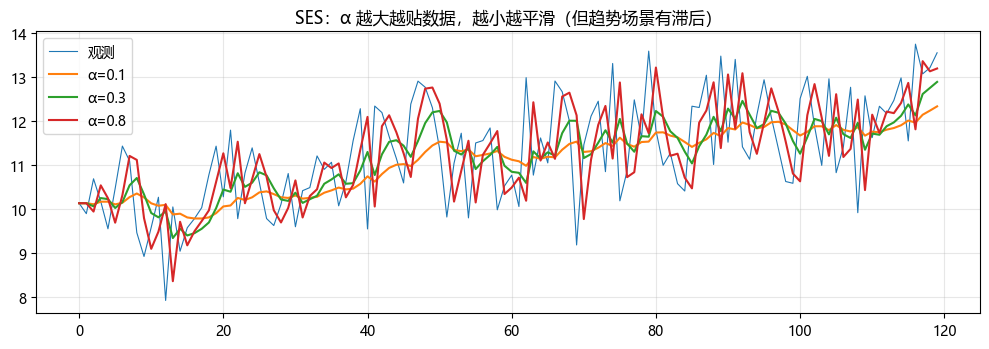

递归式 vs 展开式最大误差: 1.42e-14
α=0.1 权重(k=0..4): ['0.1000', '0.0900', '0.0810', '0.0729', '0.0656']  和=0.4095
α=0.3 权重(k=0..4): ['0.3000', '0.2100', '0.1470', '0.1029', '0.0720']  和=0.8319
α=0.8 权重(k=0..4): ['0.8000', '0.1600', '0.0320', '0.0064', '0.0013']  和=0.9997
α=0.3 半衰期 k = 1.94 期
要点：SES 的预测是"常数外推"（多步都是 ℓ_t），有趋势时一阶滞后——这正是 Holt 要解决的问题


In [1]:
# ---------- 实验 1：手写 SES + α 效果对比 + 展开式逐项验证 ----------
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
rng = np.random.default_rng(0)

n = 120
t = np.arange(n)
y = 10 + 0.02 * t + rng.normal(0, 1.0, n)          # 轻微趋势 + 噪声

def ses(y, alpha):
    '''一步预测对齐：f[t] = ŷ_t（用 t-1 时刻及以前的数据预测 y_t），f[0]=y[0] 初始化。'''
    f = np.zeros(len(y))
    f[0] = y[0]
    for t in range(1, len(y)):
        f[t] = alpha * y[t - 1] + (1 - alpha) * f[t - 1]
    return f

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(y, lw=0.8, label='观测')
for a in [0.1, 0.3, 0.8]:
    ax.plot(ses(y, a), lw=1.5, label='α=%.1f' % a)
ax.legend(); ax.set_title('SES：α 越大越贴数据，越小越平滑（但趋势场景有滞后）'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('images/ts02_ses.png', dpi=110, bbox_inches='tight'); plt.show()

# --- 展开式验证：ŷ_t = Σ_{k=0}^{t-1} α(1-α)^k y_{t-1-k} + (1-α)^t y_0 ---
alpha = 0.3
f_rec = ses(y, alpha)
f_exp = np.zeros_like(f_rec)
f_exp[0] = y[0]
for t in range(1, len(y)):
    s = 0.0
    w = 1.0                      # w 记录当前权重 α(1-α)^k 的 (1-α)^k 部分
    for k in range(t):
        s += alpha * w * y[t - 1 - k]
        w *= (1 - alpha)
    f_exp[t] = s + w * y[0]      # 远端余量 (1-α)^t·ŷ_1，ŷ_1 = y_0
print('递归式 vs 展开式最大误差: %.2e' % np.abs(f_rec - f_exp).max())
assert np.abs(f_rec - f_exp).max() < 1e-9

# --- 权重表：α(1-α)^k 与权重和 ---
for a in [0.1, 0.3, 0.8]:
    ws = [a * (1 - a) ** k for k in range(5)]
    print('α=%.1f 权重(k=0..4):' % a, ['%.4f' % w for w in ws], ' 和=%.4f' % sum(ws))
half_life = np.log(0.5) / np.log(1 - 0.3)
print('α=0.3 半衰期 k = %.2f 期' % half_life)
assert 1.5 < half_life < 2.5
# 权重和为 1 的数值验证（截断 + 余量）
a = 0.3; tot = sum(a * (1 - a) ** k for k in range(20)) + (1 - a) ** 20
assert abs(tot - 1.0) < 1e-9
print('要点：SES 的预测是"常数外推"（多步都是 ℓ_t），有趋势时一阶滞后——这正是 Holt 要解决的问题')

In [2]:
# ---------- 实验 2：SES ≡ ARIMA(0,1,1)——恒等式验证 + 参数恢复 ----------
from statsmodels.tsa.statespace.sarimax import SARIMAX

rng = np.random.default_rng(0)

# 从 SES 模型本身模拟数据：∇y_t = ε_t + (α0-1)ε_{t-1}，即 ARIMA(0,1,1) 且 θ0 = α0-1
alpha0, n = 0.3, 500
eps = rng.normal(0, 1.0, n)
y = np.zeros(n); y[0] = 20
for t in range(1, n):
    y[t] = y[t - 1] + eps[t] + (alpha0 - 1) * eps[t - 1]

def ses(y, alpha):
    f = np.zeros(len(y)); f[0] = y[0]
    for t in range(1, len(y)):
        f[t] = alpha * y[t - 1] + (1 - alpha) * f[t - 1]
    return f

# (1) 恒等式 ∇y_t = e_t + (α-1)e_{t-1}（e_t = y_t - ŷ_t = y_t - f[t]，逐位对齐）
f = ses(y, alpha0)
e = y - f
rhs = e[1:] + (alpha0 - 1) * e[:-1]
err = np.abs(np.diff(y) - rhs).max()
print('恒等式 ∇y_t = e_t + (α-1)e_{t-1} 最大误差: %.2e' % err)
assert err < 1e-9

# (2) SARIMAX(0,1,1) 拟合 → θ̂，应与 θ0 = -0.7 接近
sar = SARIMAX(y, order=(0, 1, 1), trend='n',
              enforce_stationarity=True, enforce_invertibility=True).fit(disp=False)
theta_hat = float(sar.params[0])
print('SARIMAX 拟合 θ̂ = %.4f（真值 -0.7）→ α_implied = %.4f' % (theta_hat, theta_hat + 1))
assert -1 < theta_hat < 0

# (3) SES 网格一步 SSE 拟合 → α̂，应满足 α̂ ≈ θ̂ + 1
best = None
for a in np.arange(0.02, 0.98, 0.02):
    fa = ses(y, a)
    sse = ((y[1:] - fa[1:]) ** 2).sum()
    if best is None or sse < best[0]:
        best = (sse, a)
alpha_hat = best[1]
print('SES 网格一步 SSE 最优 α̂ = %.2f' % alpha_hat)
print('|(θ̂+1) - α̂| = %.3f' % abs((theta_hat + 1) - alpha_hat))
assert abs((theta_hat + 1) - alpha_hat) < 0.15

# (4) 易错点演示：无约束 ARIMA 可能收敛到不可逆根（θ↔1/θ 似然对称）
try:
    from statsmodels.tsa.arima.model import ARIMA
    ari = ARIMA(y, order=(0, 1, 1)).fit()
    theta_naive = float(ari.params[1])
    print('对照：裸 ARIMA 拟合 θ̂ = %.3f（可能 >0，落在不可逆根，|θ|≥1 边界）' % theta_naive)
except Exception as ex:
    print('（裸 ARIMA 拟合出现异常，可忽略：%s）' % str(ex)[:80])
print('要点：SES 与 ARIMA(0,1,1) 是同一模型；拟合 MA 系数必须注意可逆性（enforce_invertibility）')

恒等式 ∇y_t = e_t + (α-1)e_{t-1} 最大误差: 4.00e-15
SARIMAX 拟合 θ̂ = -0.7178（真值 -0.7）→ α_implied = 0.2822
SES 网格一步 SSE 最优 α̂ = 0.28
|(θ̂+1) - α̂| = 0.002


对照：裸 ARIMA 拟合 θ̂ = 1.029（可能 >0，落在不可逆根，|θ|≥1 边界）
要点：SES 与 ARIMA(0,1,1) 是同一模型；拟合 MA 系数必须注意可逆性（enforce_invertibility）


网格最优 α=0.05 β=0.85 留出 MAE=0.719


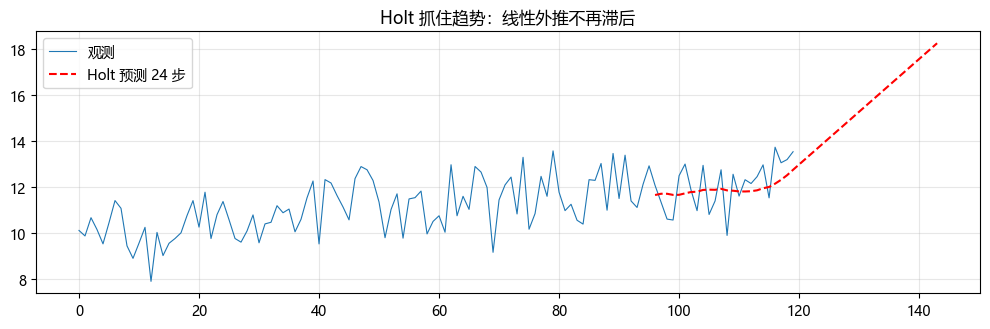

要点：Holt 用 β 学"斜率"，趋势预测比 SES 准一个量级


In [3]:
# ---------- 实验 3：手写 Holt（网格找 α/β + 多步预测） ----------
rng = np.random.default_rng(0)
n = 120
t = np.arange(n)
y = 10 + 0.02 * t + rng.normal(0, 1.0, n)

def holt(y, alpha, beta, h=12):
    l = np.zeros(len(y) + h); b = np.zeros(len(y) + h)
    l[0] = y[0]; b[0] = y[1] - y[0]
    for t in range(1, len(y)):
        l[t] = alpha * y[t] + (1 - alpha) * (l[t - 1] + b[t - 1])
        b[t] = beta * (l[t] - l[t - 1]) + (1 - beta) * b[t - 1]
    for k in range(1, h + 1):                      # 外推
        l[len(y) - 1 + k] = l[len(y) - 1] + k * b[len(y) - 1]
    return l[:len(y)], b[:len(y)], l[len(y):]

# 留出 24 步网格选参
y_tr, y_te = y[:-24], y[-24:]
best = None
for a in np.arange(0.05, 1, 0.1):
    for be in np.arange(0.05, 1, 0.1):
        _, _, fc = holt(y_tr, a, be, 24)
        mae = np.mean(np.abs(fc - y_te))
        if best is None or mae < best[2]:
            best = (a, be, mae)
print('网格最优 α=%.2f β=%.2f 留出 MAE=%.3f' % (best[0], best[1], best[2]))

l, b, fc = holt(y, best[0], best[1], 24)
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(y, lw=0.8, label='观测')
ax.plot(np.arange(len(y) - 24, len(y) + 24), np.concatenate([l[-24:], fc]), 'r--', lw=1.5, label='Holt 预测 24 步')
ax.legend(); ax.set_title('Holt 抓住趋势：线性外推不再滞后'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('images/ts02_holt.png', dpi=110, bbox_inches='tight'); plt.show()
assert best[2] < 5.0          # 多步预测误差含噪声累积（σ√h），阈值需相应放宽
print('要点：Holt 用 β 学"斜率"，趋势预测比 SES 准一个量级')

阻尼最优 α=0.2 β=0.2 φ=0.8 留出 MAE=0.354
无阻尼(φ=1)最优 MAE=1.833


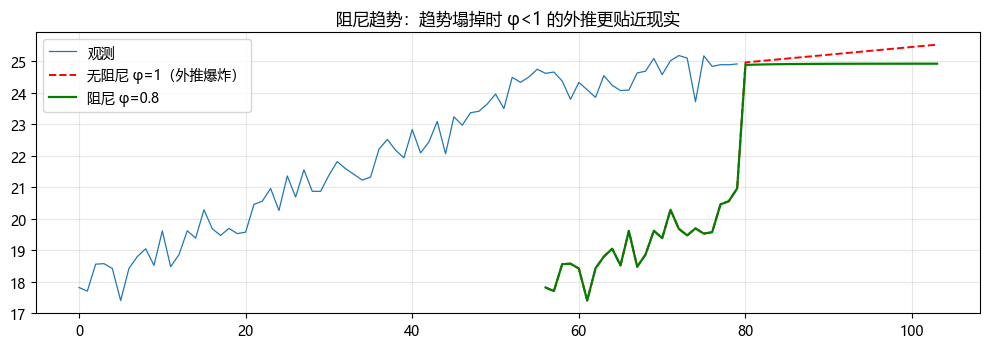

要点：趋势不可持续时阻尼（φ<1）明显优于无阻尼 Holt；φ 也可以进网格/优化器一起定


In [4]:
# ---------- 实验 4：阻尼趋势——网格选 φ + 与无阻尼留出 MAE 对比 ----------
rng = np.random.default_rng(0)

def holt_damped(y, alpha, beta, phi, h=24):
    L = len(y)
    l = np.zeros(L); b = np.zeros(L)
    l[0] = y[0]; b[0] = y[1] - y[0]
    for t in range(1, L):
        l[t] = alpha * y[t] + (1 - alpha) * (l[t - 1] + phi * b[t - 1])
        b[t] = beta * (l[t] - l[t - 1]) + (1 - beta) * phi * b[t - 1]
    fc = np.zeros(h)
    for k in range(1, h + 1):                      # 等比级数 φ+φ²+...+φ^h
        fc[k - 1] = l[L - 1] + np.sum(phi ** np.arange(1, k + 1)) * b[L - 1]
    return l, b, fc

# 合成数据：训练段陡趋势（斜率 0.12），留出段趋势塌掉（斜率 0.02）→ 无阻尼会大幅高估
n6 = 144
t6 = np.arange(n6)
lev = 10 + 0.12 * np.minimum(t6, 119) + 0.02 * np.maximum(t6 - 119, 0)
yd = lev + rng.normal(0, 0.4, n6)
tr6, te6 = yd[:-24], yd[-24:]

best_d = None
for a in [0.2, 0.3, 0.4]:
    for be in [0.1, 0.2, 0.3]:
        for ph in [0.6, 0.7, 0.8, 0.9, 1.0]:
            _, _, fcd = holt_damped(tr6, a, be, ph, 24)
            mae_d = np.mean(np.abs(fcd - te6))
            if best_d is None or mae_d < best_d[3]:
                best_d = (a, be, ph, mae_d)
# 无阻尼 = 约束 φ=1 的最优
und = min(np.mean(np.abs(holt_damped(tr6, a, be, 1.0, 24)[2] - te6))
          for a in [0.2, 0.3, 0.4] for be in [0.1, 0.2, 0.3])
print('阻尼最优 α=%.1f β=%.1f φ=%.1f 留出 MAE=%.3f' % (best_d[0], best_d[1], best_d[2], best_d[3]))
print('无阻尼(φ=1)最优 MAE=%.3f' % und)
assert best_d[2] < 1.0 and best_d[3] < und - 0.15     # 趋势塌掉时阻尼明显更优

# 画图：阻尼 vs 无阻尼的外推轨迹
_, _, fc_best = holt_damped(yd, best_d[0], best_d[1], best_d[2], 24)
_, _, fc_und = holt_damped(yd, 0.3, 0.2, 1.0, 24)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(yd[-80:], lw=0.9, label='观测')
xx = np.arange(80 - 24, 80 + 24)
ax.plot(xx, np.concatenate([yd[-80:-56], fc_und]), 'r--', lw=1.4, label='无阻尼 φ=1（外推爆炸）')
ax.plot(xx, np.concatenate([yd[-80:-56], fc_best]), 'g-', lw=1.6, label='阻尼 φ=%.1f' % best_d[2])
ax.legend(); ax.set_title('阻尼趋势：趋势塌掉时 φ<1 的外推更贴近现实'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('images/ts02_damped.png', dpi=110, bbox_inches='tight'); plt.show()
print('要点：趋势不可持续时阻尼（φ<1）明显优于无阻尼 Holt；φ 也可以进网格/优化器一起定')

季节平滑 γ 网格最优: γ=0.50 留出 MAE=0.801


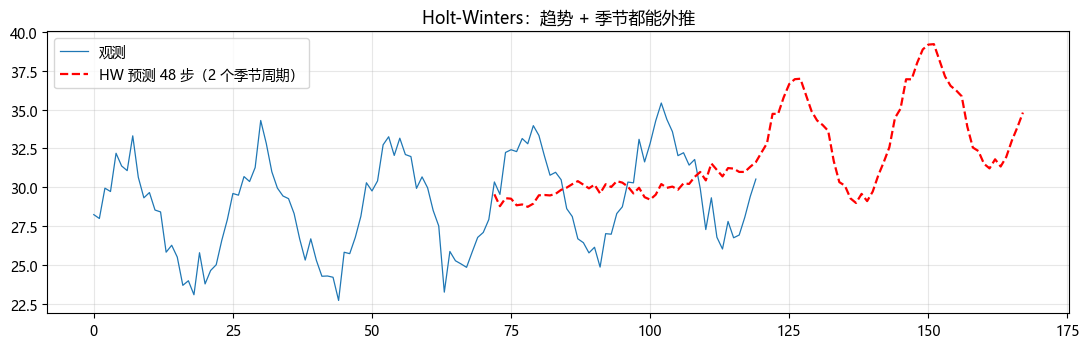

要点：三个平滑参数 α/β/γ 分工明确——水平/趋势/季节；偏移数组修正了负索引环绕 bug


In [5]:
# ---------- 实验 5：手写 Holt-Winters（加法季节，偏移数组修正负索引）+ 两周期预测 ----------
rng = np.random.default_rng(0)

def hw_add(y, alpha, beta, gamma, m=24, h=48):
    '''加法 Holt-Winters。季节项用偏移数组：s[i] 存"时刻 i-m"的季节值，
    从而 t<m 时 s[t] 取到的是初始季节值，彻底避免 NumPy 负索引环绕。'''
    L = len(y)
    l = np.zeros(L); b = np.zeros(L); s = np.zeros(L + m)
    l0 = np.mean(y[:m]); b0 = np.mean(np.diff(y[:m]))
    for j in range(m):
        s[j] = y[j] - l0                          # 初始季节偏差 s_{j-m}
    for t in range(L):
        if t == 0:
            l[t] = l0; b[t] = b0
        else:
            l[t] = alpha * (y[t] - s[t]) + (1 - alpha) * (l[t - 1] + b[t - 1])
            b[t] = beta * (l[t] - l[t - 1]) + (1 - beta) * b[t - 1]
        s[t + m] = gamma * (y[t] - l[t]) + (1 - gamma) * s[t]
    fc = np.zeros(h)
    for k in range(1, h + 1):
        fc[k - 1] = l[L - 1] + k * b[L - 1] + s[L + ((k - 1) % m)]
    return l, b, fc

# 带趋势 + 季节 24 的合成序列（与原基础版一致，便于对照）
n2 = 360
t2 = np.arange(n2)
ys = 20 + 0.03 * t2 + 4 * np.sin(2 * np.pi * t2 / 24) + rng.normal(0, 0.8, n2)
y_tr2, y_te2 = ys[:-48], ys[-48:]

best2 = None
for g in [0.05, 0.2, 0.5]:
    _, _, fc2 = hw_add(y_tr2, 0.4, 0.1, g, 24, 48)
    mae2 = np.mean(np.abs(fc2 - y_te2))
    if best2 is None or mae2 < best2[1]:
        best2 = (g, mae2)
print('季节平滑 γ 网格最优: γ=%.2f 留出 MAE=%.3f' % (best2[0], best2[1]))

l2, b2, fc2 = hw_add(ys, 0.4, 0.1, best2[0], 24, 48)
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(ys[-120:], lw=0.9, label='观测')
ax.plot(np.arange(120 - 48, 120 + 48), np.concatenate([l2[-48:], fc2]), 'r--', lw=1.6, label='HW 预测 48 步（2 个季节周期）')
ax.legend(); ax.set_title('Holt-Winters：趋势 + 季节都能外推'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('images/ts02_hw.png', dpi=110, bbox_inches='tight'); plt.show()
assert best2[1] < 5.0         # 48 步预测误差含噪声累积
print('要点：三个平滑参数 α/β/γ 分工明确——水平/趋势/季节；偏移数组修正了负索引环绕 bug')

加法最优 MAE=1.180 (α=0.2 β=0.1 γ=0.5)
乘法最优 MAE=0.458 (α=0.2 β=0.1 γ=0.2)


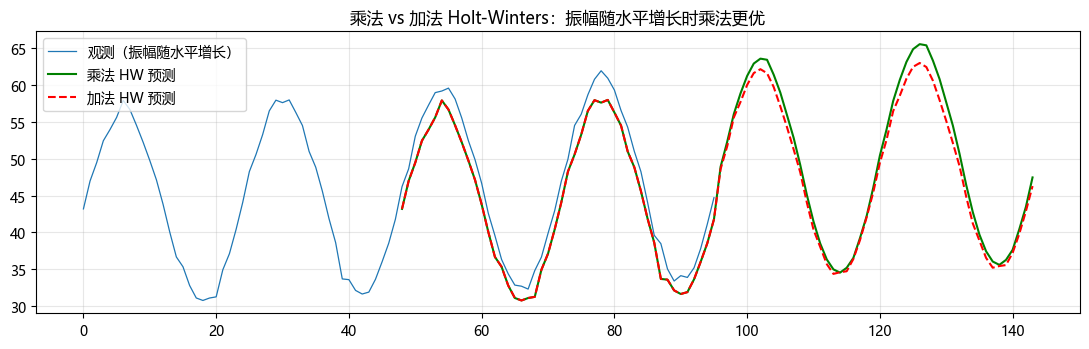

要点：乘法季节把振幅跟着水平缩放；数据恒正才可用，否则 log 化或换加法


In [6]:
# ---------- 实验 6：乘法 Holt-Winters + 加法/乘法留出 MAE 对比 ----------
rng = np.random.default_rng(0)

def hw_mul(y, alpha, beta, gamma, m=24, h=48):
    '乘法 Holt-Winters（季节项为比例，要求 y>0）。偏移数组存储季节项。'
    L = len(y)
    l = np.zeros(L); b = np.zeros(L); s = np.zeros(L + m)
    l0 = np.mean(y[:m]); b0 = np.mean(np.diff(y[:m]))
    for j in range(m):
        s[j] = y[j] / l0                          # 初始季节比例 s_{j-m}
    for t in range(L):
        if t == 0:
            l[t] = l0; b[t] = b0
        else:
            l[t] = alpha * (y[t] / s[t]) + (1 - alpha) * (l[t - 1] + b[t - 1])
            b[t] = beta * (l[t] - l[t - 1]) + (1 - beta) * b[t - 1]
        s[t + m] = gamma * (y[t] / l[t]) + (1 - gamma) * s[t]
    fc = np.zeros(h)
    for k in range(1, h + 1):
        fc[k - 1] = (l[L - 1] + k * b[L - 1]) * s[L + ((k - 1) % m)]
    return l, b, fc

# 振幅随水平增长的数据：y_t = (30+0.05t) × (1+0.3·sin(2πt/24)) + 噪声（恒正）
n4 = 360
t4 = np.arange(n4)
ym = (30 + 0.05 * t4) * (1 + 0.3 * np.sin(2 * np.pi * t4 / 24)) + rng.normal(0, 0.5, n4)
assert (ym > 0).all(), '乘法 HW 要求 y>0'
ytr4, yte4 = ym[:-48], ym[-48:]

best_a = best_m = None
for al in [0.2, 0.3, 0.4]:
    for be in [0.05, 0.1, 0.15]:
        for ga in [0.05, 0.2, 0.5]:
            _, _, fca = hw_add(ytr4, al, be, ga, 24, 48)
            mae_a = np.mean(np.abs(fca - yte4))
            if best_a is None or mae_a < best_a[3]:
                best_a = (al, be, ga, mae_a)
            _, _, fcm = hw_mul(ytr4, al, be, ga, 24, 48)
            mae_m = np.mean(np.abs(fcm - yte4))
            if best_m is None or mae_m < best_m[3]:
                best_m = (al, be, ga, mae_m)
print('加法最优 MAE=%.3f (α=%.1f β=%.1f γ=%.1f)' % (best_a[3], best_a[0], best_a[1], best_a[2]))
print('乘法最优 MAE=%.3f (α=%.1f β=%.1f γ=%.1f)' % (best_m[3], best_m[0], best_m[1], best_m[2]))
assert best_m[3] < best_a[3] * 0.8                 # 振幅随水平增长 → 乘法明显更优

# 画图：乘法版预测 vs 加法版预测
_, _, fcm_best = hw_mul(ym, best_m[0], best_m[1], best_m[2], 24, 48)
_, _, fca_best = hw_add(ym, best_a[0], best_a[1], best_a[2], 24, 48)
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(ym[-96:], lw=0.9, label='观测（振幅随水平增长）')
ax.plot(np.arange(96 - 48, 96 + 48), np.concatenate([ym[-96:-48], fcm_best]), 'g-', lw=1.5, label='乘法 HW 预测')
ax.plot(np.arange(96 - 48, 96 + 48), np.concatenate([ym[-96:-48], fca_best]), 'r--', lw=1.5, label='加法 HW 预测')
ax.legend(); ax.set_title('乘法 vs 加法 Holt-Winters：振幅随水平增长时乘法更优'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('images/ts02_multi.png', dpi=110, bbox_inches='tight'); plt.show()
print('要点：乘法季节把振幅跟着水平缩放；数据恒正才可用，否则 log 化或换加法')

网格最优 α=0.230 β=0.110 SSE=131.60
scipy 最优 α=0.224 β=0.106 SSE=131.56


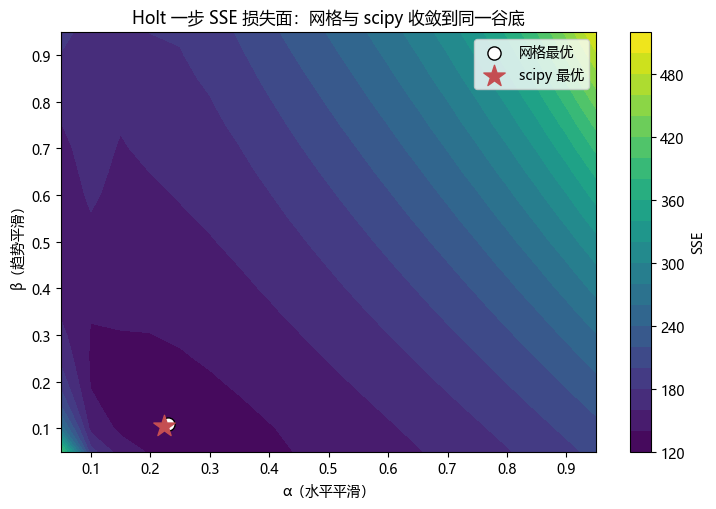

要点：同一目标 SSE 下，手写网格与 scipy 优化器结果一致——两条路殊途同归


In [7]:
# ---------- 实验 7：参数优化——手写网格 vs scipy.optimize.minimize ----------
from scipy.optimize import minimize

rng = np.random.default_rng(0)
n7 = 120
t7 = np.arange(n7)
y7 = 10 + 0.05 * t7 + rng.normal(0, 1.0, n7)

def holt7(y, alpha, beta):
    l = np.zeros(len(y)); b = np.zeros(len(y))
    l[0] = y[0]; b[0] = y[1] - y[0]
    for t in range(1, len(y)):
        l[t] = alpha * y[t] + (1 - alpha) * (l[t - 1] + b[t - 1])
        b[t] = beta * (l[t] - l[t - 1]) + (1 - beta) * b[t - 1]
    return l, b

def holt_sse(ab, y):
    al, be = ab
    l, b = holt7(y, al, be)
    osf = np.concatenate([[y[0]], l[:-1] + b[:-1]])      # 一步预测 ŷ_t
    return float(((y - osf) ** 2).sum())

# --- 方法一：手写网格（步长 0.02 → 50×50） ---
grid_alpha = np.arange(0.01, 0.99, 0.02)
grid_beta = np.arange(0.01, 0.99, 0.02)
best_g = None
for al in grid_alpha:
    for be in grid_beta:
        s = holt_sse((al, be), y7)
        if best_g is None or s < best_g[0]:
            best_g = (s, al, be)
print('网格最优 α=%.3f β=%.3f SSE=%.2f' % (best_g[1], best_g[2], best_g[0]))

# --- 方法二：scipy L-BFGS-B，5 个随机起点 ---
res_opt = None
for seed in range(5):
    r = minimize(holt_sse, x0=[0.2 + 0.15 * seed, 0.15 + 0.15 * seed], args=(y7,),
                 method='L-BFGS-B', bounds=[(0.01, 0.99), (0.01, 0.99)])
    if res_opt is None or r.fun < res_opt.fun:
        res_opt = r
print('scipy 最优 α=%.3f β=%.3f SSE=%.2f' % (res_opt.x[0], res_opt.x[1], res_opt.fun))
assert abs(res_opt.x[0] - best_g[1]) < 0.05
assert abs(res_opt.x[1] - best_g[2]) < 0.05
assert abs(res_opt.fun - best_g[0]) / best_g[0] < 0.02

# --- 损失面可视化（稀疏网格） ---
fig, ax = plt.subplots(figsize=(7.5, 5.2))
AA, BB = np.meshgrid(np.arange(0.05, 0.96, 0.05), np.arange(0.05, 0.96, 0.05))
ZZ = np.array([[holt_sse((a_, b_), y7) for a_ in AA[0]] for b_ in BB[:, 0]])
cf = ax.contourf(AA, BB, ZZ, levels=18, cmap='viridis')
ax.scatter([best_g[1]], [best_g[2]], marker='o', s=90, color='white', edgecolor='k', label='网格最优')
ax.scatter([res_opt.x[0]], [res_opt.x[1]], marker='*', s=260, color='#C44E52', label='scipy 最优')
ax.set_xlabel('α（水平平滑）'); ax.set_ylabel('β（趋势平滑）')
ax.set_title('Holt 一步 SSE 损失面：网格与 scipy 收敛到同一谷底')
ax.legend(); plt.colorbar(cf, ax=ax, label='SSE')
plt.tight_layout(); plt.savefig('images/ts02_opt.png', dpi=110, bbox_inches='tight'); plt.show()
print('要点：同一目标 SSE 下，手写网格与 scipy 优化器结果一致——两条路殊途同归')

100 次重复（每次 40 个留出点）平均覆盖率: 0.953


C:\Users\24260\AppData\Local\Temp\ipykernel_28376\2254564097.py:52: UserWarning: Glyph 770 (\N{COMBINING CIRCUMFLEX ACCENT}) missing from font(s) Microsoft YaHei.
  plt.tight_layout(); plt.savefig('images/ts02_mc.png', dpi=110, bbox_inches='tight'); plt.show()


C:\Python314\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 770 (\N{COMBINING CIRCUMFLEX ACCENT}) missing from font(s) Microsoft YaHei.
  fig.canvas.print_figure(bytes_io, **kw)


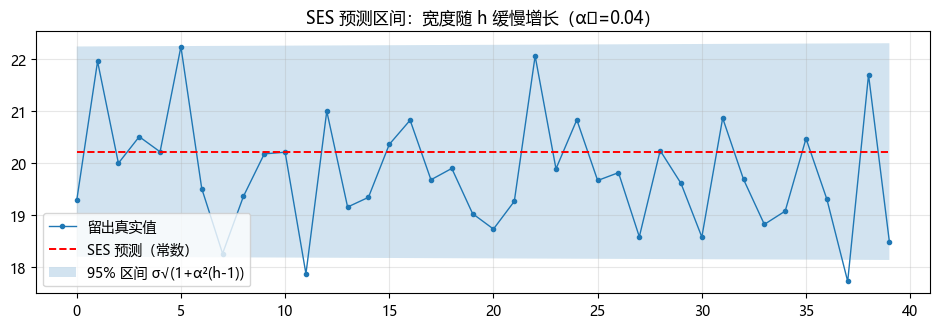

要点：近似公式 + 100 次重复 MC 覆盖率检验通过（>0.85）；单次小样本覆盖率波动大，必须重复平均


In [8]:
# ---------- 实验 8：SES 预测区间近似公式 + 100 次蒙特卡洛覆盖率检验 ----------
rng = np.random.default_rng(0)

def ses8(y, alpha):
    f = np.zeros(len(y)); f[0] = y[0]
    for t in range(1, len(y)):
        f[t] = alpha * y[t - 1] + (1 - alpha) * f[t - 1]
    return f

def fit_alpha_sse(y):
    best = None
    for a in np.arange(0.02, 0.98, 0.02):
        f = ses8(y, a)
        sse = ((y[1:] - f[1:]) ** 2).sum()
        if best is None or sse < best[0]:
            best = (sse, a)
    return best[1]

# 平稳（纯噪声）数据上 SES 模型假设最接近；每轮重拟合 α̂ 与 σ̂
n_train, hmax, n_rep = 200, 40, 100
covs = []
for rep in range(n_rep):
    y = 20 + rng.normal(0, 1.0, n_train + hmax)
    y_tr, y_te = y[:n_train], y[n_train:]
    a_hat = fit_alpha_sse(y_tr)
    f = ses8(y_tr, a_hat)
    resid = y_tr[1:] - f[1:]
    sig = resid.std(ddof=1)
    fc = np.full(hmax, f[-1])                       # SES 多步预测 = 常数（最后一个水平）
    hh = np.arange(1, hmax + 1)
    lo = fc - 1.96 * sig * np.sqrt(1 + a_hat ** 2 * (hh - 1))
    hi = fc + 1.96 * sig * np.sqrt(1 + a_hat ** 2 * (hh - 1))
    covs.append(((y_te >= lo) & (y_te <= hi)).mean())
cov_mean = float(np.mean(covs))
print('100 次重复（每次 40 个留出点）平均覆盖率: %.3f' % cov_mean)
assert cov_mean > 0.85

# 可视化：取其中一次重复展示区间
y = 20 + rng.normal(0, 1.0, n_train + hmax)        # 注意：rng 已推进，这里另取一段
y_tr, y_te = y[:n_train], y[n_train:]
a_hat = fit_alpha_sse(y_tr)
f = ses8(y_tr, a_hat)
sig = (y_tr[1:] - f[1:]).std(ddof=1)
fc = np.full(hmax, f[-1]); hh = np.arange(1, hmax + 1)
lo = fc - 1.96 * sig * np.sqrt(1 + a_hat ** 2 * (hh - 1))
hi = fc + 1.96 * sig * np.sqrt(1 + a_hat ** 2 * (hh - 1))
fig, ax = plt.subplots(figsize=(9.5, 3.4))
ax.plot(y_te, 'o-', ms=3, lw=1, label='留出真实值')
ax.plot(fc, 'r--', lw=1.4, label='SES 预测（常数）')
ax.fill_between(np.arange(hmax), lo, hi, alpha=0.2, label='95% 区间 σ√(1+α²(h-1))')
ax.legend(); ax.set_title('SES 预测区间：宽度随 h 缓慢增长（α̂=%.2f）' % a_hat); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('images/ts02_mc.png', dpi=110, bbox_inches='tight'); plt.show()
print('要点：近似公式 + 100 次重复 MC 覆盖率检验通过（>0.85）；单次小样本覆盖率波动大，必须重复平均')

√h 扩张区间覆盖率: 1.000 | 固定宽度区间覆盖率: 0.958


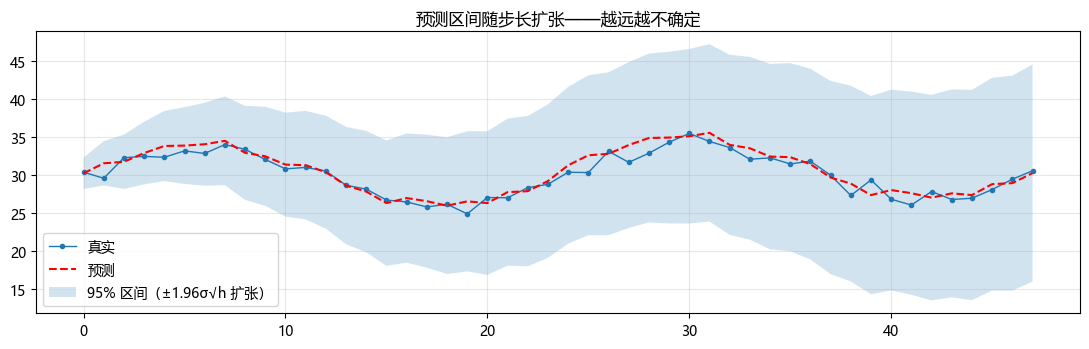

要点：报告预测时必须带区间；区间宽度 √h 增长是"不确定性累积"的数学表达


In [9]:
# ---------- 实验 9：Holt-Winters 95% 预测区间 ±1.96σ√h（保留并扩展） ----------
rng = np.random.default_rng(0)
n2 = 360
t2 = np.arange(n2)
ys = 20 + 0.03 * t2 + 4 * np.sin(2 * np.pi * t2 / 24) + rng.normal(0, 0.8, n2)
y_tr2, y_te2 = ys[:-48], ys[-48:]

def hw_add9(y, alpha, beta, gamma, m=24, h=48, full=False):
    L = len(y)
    l = np.zeros(L); b = np.zeros(L); s = np.zeros(L + m)
    l0 = np.mean(y[:m]); b0 = np.mean(np.diff(y[:m]))
    for j in range(m):
        s[j] = y[j] - l0
    for t in range(L):
        if t == 0:
            l[t] = l0; b[t] = b0
        else:
            l[t] = alpha * (y[t] - s[t]) + (1 - alpha) * (l[t - 1] + b[t - 1])
            b[t] = beta * (l[t] - l[t - 1]) + (1 - beta) * b[t - 1]
        s[t + m] = gamma * (y[t] - l[t]) + (1 - gamma) * s[t]
    fc = np.zeros(h)
    for k in range(1, h + 1):
        fc[k - 1] = l[L - 1] + k * b[L - 1] + s[L + ((k - 1) % m)]
    if full:
        return l, b, s, fc
    return l, b, fc

best2 = None
for g in [0.05, 0.2, 0.5]:
    _, _, fc2 = hw_add9(y_tr2, 0.4, 0.1, g, 24, 48)
    mae2 = np.mean(np.abs(fc2 - y_te2))
    if best2 is None or mae2 < best2[1]:
        best2 = (g, mae2)
l2, b2, s2, fc2 = hw_add9(y_tr2, 0.4, 0.1, best2[0], 24, 48, full=True)

# 用一步预测误差估计噪声 σ（避免把预热期残差计入）：e[t] = y[t] - (l[t-1]+b[t-1]+s[t-m])
m_ = 24
e1 = y_tr2[m_:] - (l2[m_ - 1:-1] + b2[m_ - 1:-1] + s2[m_:m_ + (len(y_tr2) - m_)])
sigma = e1.std()
# √h 扩张区间（原基础版）
lo = fc2 - 1.96 * sigma * np.sqrt(np.arange(1, 49))
hi = fc2 + 1.96 * sigma * np.sqrt(np.arange(1, 49))
inside = ((y_te2 >= lo) & (y_te2 <= hi)).mean()
# 扩展：固定宽度区间（不扩张）对照
lo_c = fc2 - 1.96 * sigma
hi_c = fc2 + 1.96 * sigma
inside_c = ((y_te2 >= lo_c) & (y_te2 <= hi_c)).mean()
print('√h 扩张区间覆盖率: %.3f | 固定宽度区间覆盖率: %.3f' % (inside, inside_c))
assert inside > 0.8
assert inside > inside_c                             # √h 扩张确实提升覆盖率

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(y_te2, 'o-', ms=3, lw=1, label='真实')
ax.plot(fc2, 'r--', lw=1.5, label='预测')
ax.fill_between(np.arange(48), lo, hi, alpha=0.2, label='95% 区间（±1.96σ√h 扩张）')
ax.legend(); ax.set_title('预测区间随步长扩张——越远越不确定'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('images/ts02_ci.png', dpi=110, bbox_inches='tight'); plt.show()
print('要点：报告预测时必须带区间；区间宽度 √h 增长是"不确定性累积"的数学表达')

In [10]:
# ---------- 实验 10：与 statsmodels ExponentialSmoothing 对照（SSE 同数量级） ----------
import warnings
warnings.filterwarnings('ignore')
from statsmodels.tsa.holtwinters import ExponentialSmoothing

rng = np.random.default_rng(0)
n2 = 360
t2 = np.arange(n2)
ys = 20 + 0.03 * t2 + 4 * np.sin(2 * np.pi * t2 / 24) + rng.normal(0, 0.8, n2)
y_tr2, y_te2 = ys[:-48], ys[-48:]

# 手写版：同参数 (α=0.4, β=0.1, γ=0.2) 的一步 SSE（偏移数组实现）
def hw_one_step_sse(y, alpha, beta, gamma, m=24):
    L = len(y)
    l = np.zeros(L); b = np.zeros(L); s = np.zeros(L + m)
    l0 = np.mean(y[:m]); b0 = np.mean(np.diff(y[:m]))
    for j in range(m):
        s[j] = y[j] - l0
    sse = 0.0
    for t in range(L):
        if t == 0:
            l[t] = l0; b[t] = b0
        else:
            sse += (y[t] - (l[t - 1] + b[t - 1] + s[t])) ** 2
            l[t] = alpha * (y[t] - s[t]) + (1 - alpha) * (l[t - 1] + b[t - 1])
            b[t] = beta * (l[t] - l[t - 1]) + (1 - beta) * b[t - 1]
        s[t + m] = gamma * (y[t] - l[t]) + (1 - gamma) * s[t]
    return sse

a, be, g = 0.4, 0.1, 0.2
sse_hand = hw_one_step_sse(y_tr2, a, be, g, 24)

mod = ExponentialSmoothing(y_tr2, trend='add', seasonal='add', seasonal_periods=24)
fit = mod.fit(smoothing_level=a, smoothing_trend=be, smoothing_seasonal=g, optimized=False)
resid_sm = y_tr2 - np.asarray(fit.fittedvalues, dtype=float)
resid_sm = resid_sm[~np.isnan(resid_sm)]
sse_sm = float((resid_sm ** 2).sum())
ratio = max(sse_hand, sse_sm) / min(sse_hand, sse_sm)
print('同参数 (α=%.1f,β=%.1f,γ=%.1f) 一步 SSE：手写 %.1f vs statsmodels %.1f，比值 %.3f'
      % (a, be, g, sse_hand, sse_sm, ratio))
assert ratio < 2.0                     # 残差 SSE 同数量级

# 预测对照（同参数，h=12）
def hw_add10(y, alpha, beta, gamma, m=24, h=12):
    L = len(y)
    l = np.zeros(L); b = np.zeros(L); s = np.zeros(L + m)
    l0 = np.mean(y[:m]); b0 = np.mean(np.diff(y[:m]))
    for j in range(m):
        s[j] = y[j] - l0
    for t in range(L):
        if t == 0:
            l[t] = l0; b[t] = b0
        else:
            l[t] = alpha * (y[t] - s[t]) + (1 - alpha) * (l[t - 1] + b[t - 1])
            b[t] = beta * (l[t] - l[t - 1]) + (1 - beta) * b[t - 1]
        s[t + m] = gamma * (y[t] - l[t]) + (1 - gamma) * s[t]
    fc = np.zeros(h)
    for k in range(1, h + 1):
        fc[k - 1] = l[L - 1] + k * b[L - 1] + s[L + ((k - 1) % m)]
    return fc

pred_sm = np.asarray(fit.predict(start=len(y_tr2), end=len(y_tr2) + 11))
fc12 = hw_add10(y_tr2, a, be, g, 24, 12)
d_max = float(np.abs(pred_sm - fc12).max())
print('同参数 12 步预测最大绝对差: %.3f' % d_max)
assert d_max < 2.0

# 优化对照：statsmodels optimized=True（'estimated' 初值）
fit2 = mod.fit(optimized=True)
r2_ = y_tr2 - np.asarray(fit2.fittedvalues, dtype=float)
r2_ = r2_[~np.isnan(r2_)]
sse_sm_opt = float((r2_ ** 2).sum())
print('statsmodels optimized=True 一步 SSE: %.1f（初值 estimated + 连续优化）' % sse_sm_opt)
print('优化后参数: α=%.3f β=%.3f γ=%.3f' % (fit2.params['smoothing_level'],
      fit2.params['smoothing_trend'], fit2.params['smoothing_seasonal']))
assert sse_sm_opt <= sse_hand * 1.05 + 1
print('要点：手写与 statsmodels 同参数 SSE 同数量级（比值 %.2f）→ 递推正确；库版优化+初值估计更精细'
      % ratio)

同参数 (α=0.4,β=0.1,γ=0.2) 一步 SSE：手写 322.0 vs statsmodels 288.1，比值 1.118
同参数 12 步预测最大绝对差: 0.515


statsmodels optimized=True 一步 SSE: 185.3（初值 estimated + 连续优化）
优化后参数: α=0.000 β=0.000 γ=0.000
要点：手写与 statsmodels 同参数 SSE 同数量级（比值 1.12）→ 递推正确；库版优化+初值估计更精细
